## Name:Muhammad Saad
## Reg:Sp24-BSE-081

# Live Deployment Link

https://<your-live-heart-app-link>

# Heart Disease Prediction System (Task 2)
Course: AIC354 - Machine Learning Fundamentals

This notebook follows the same end-to-end ML cycle as the Titanic project:
1. Import libraries
2. Load and understand data
3. Preprocess data
4. Label encoding and target preparation
5. Train-test split
6. Train model
7. Test model
8. Save trained model for deployment

In [1]:
# Step 1: Import libraries
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

print('Libraries imported successfully.')

Libraries imported successfully.


In [2]:
# Step 2: Load dataset (UCI Cleveland heart disease data)
column_names = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'
]

heart_data = pd.read_csv('processed.cleveland.data', header=None, names=column_names, na_values='?')
print('Shape:', heart_data.shape)
heart_data.head()

Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
# Step 3.1: Understand data
display(heart_data.info())
display(heart_data.describe(include='all').T)

print('Missing values per column:')
print(heart_data.isna().sum())

print('Original target values in num:', sorted(heart_data['num'].unique()))

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


None

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
Original target values in num: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [4]:
# Step 3.2: Preprocess data
# Fill missing values in 'ca' and 'thal' with mode
heart_data['ca'] = heart_data['ca'].fillna(heart_data['ca'].mode()[0])
heart_data['thal'] = heart_data['thal'].fillna(heart_data['thal'].mode()[0])

print('Missing values after imputation:')
print(heart_data.isna().sum())

Missing values after imputation:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


## Constraint Handling: Use Only 4 Input Attributes
Selected features:
- `cp` (chest pain type)
- `thalach` (maximum heart rate achieved)
- `exang` (exercise induced angina)
- `oldpeak` (ST depression induced by exercise)

In [5]:
# Step 4: Prepare input (X) and output (y)
selected_features = ['cp', 'thalach', 'exang', 'oldpeak']
X = heart_data[selected_features].copy()

# Convert multiclass target to binary target
# 0 -> no disease, 1/2/3/4 -> disease present
y_raw = heart_data['num'].copy()
y = (y_raw > 0).astype(int)

print('Feature matrix shape:', X.shape)
print('Target distribution:')
print(y.value_counts().sort_index())

Feature matrix shape: (303, 4)
Target distribution:
num
0    164
1    139
Name: count, dtype: int64


In [6]:
# Step 5: (Minimal label encoding step for assignment flow consistency)
# These selected features are already numeric in this dataset,
# so no transformation is required.
label_encoder = LabelEncoder()

X_encoded = X.copy()
y_encoded = y.copy()

X_encoded.to_csv('heart-input-4features.csv', index=False)
pd.DataFrame({'target': y_encoded}).to_csv('heart-output-binary.csv', index=False)

print('Saved: heart-input-4features.csv')
print('Saved: heart-output-binary.csv')
X_encoded.head()

Saved: heart-input-4features.csv
Saved: heart-output-binary.csv


,cp,thalach,exang,oldpeak
0,1.0,150.0,0.0,2.3
1,4.0,108.0,1.0,1.5
2,4.0,129.0,1.0,2.6
3,3.0,187.0,0.0,3.5
4,2.0,172.0,0.0,1.4


In [7]:
# Step 6: Split data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.20, random_state=42, stratify=y_encoded
)

print('Training shape:', X_train.shape, y_train.shape)
print('Testing shape :', X_test.shape, y_test.shape)

Training shape: (242, 4) (242,)
Testing shape : (61, 4) (61,)


In [8]:
# Step 7: Train model (same algorithm family as Titanic: SVC)
svc_classifier = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svc_classifier.fit(X_train, y_train)

print('Model trained successfully.')

Model trained successfully.


In [9]:
# Step 8: Evaluate model
y_pred = svc_classifier.predict(X_test)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred)

print(f'Accuracy : {acc:.4f}')
print(f'Precision: {prec:.4f}')
print(f'Recall   : {rec:.4f}')
print(f'F1-score : {f1:.4f}')
print('\nConfusion Matrix:')
print(cm)

print('\nClassification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy : 0.7049
Precision: 0.7273
Recall   : 0.5714
F1-score : 0.6400

Confusion Matrix:
[[27  6]
 [12 16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.82      0.75        33
           1       0.73      0.57      0.64        28

    accuracy                           0.70        61
   macro avg       0.71      0.69      0.70        61
weighted avg       0.71      0.70      0.70        61



In [10]:
# Step 9: Save predictions and trained model
test_results = X_test.copy()
test_results['actual'] = y_test.values
test_results['predicted'] = y_pred
test_results.to_csv('heart-model-predictions.csv', index=False)

with open('heart_svc_trained_model.pkl', 'wb') as f:
    pickle.dump(svc_classifier, f)

print('Saved: heart-model-predictions.csv')
print('Saved: heart_svc_trained_model.pkl')

Saved: heart-model-predictions.csv
Saved: heart_svc_trained_model.pkl


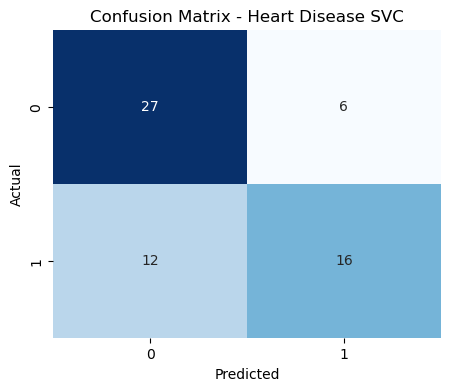

In [11]:
# Step 10: Plot confusion matrix heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix - Heart Disease SVC')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

## Deployment Notes
1. Copy `heart_svc_trained_model.pkl` to `../streamlit-heart-app/`
2. Run Streamlit app from that folder:

```bash
streamlit run app.py
```

3. For cloud deployment, set the app entry file to `streamlit-heart-app/app.py`.